Step 0: mount google drive

In [1]:
# Cell 1: connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Step 1: Production forecast dates

In [2]:
import os

# 0b. Paths. Change these only if your folders are named differently.
PROJECT = "/content/drive/MyDrive/volve-forecasting"   # results are saved here
SRC = "/content/drive/MyDrive/petro"                    # this notebook's folder

DATA_FILE_NAME = "Volve production data.xlsx"

# Forecast dates
VAL_START = "2014-10-01"     # practice year starts (week of 29 Sep 2014)
TEST_START = "2015-10-01"    # test year starts (week of 28 Sep 2015)
HORIZON = 52                 # weeks to forecast

Step 2: Import Libraries

In [3]:
# 0c. Imports, folders and chart style
import glob, math, os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.optimize import curve_fit, OptimizeWarning
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore", category=OptimizeWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

OUT = Path(PROJECT) / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

VAL_ORIGIN = pd.Timestamp(VAL_START).to_period("W-SUN").start_time    # a Monday
TEST_ORIGIN = pd.Timestamp(TEST_START).to_period("W-SUN").start_time

COLORS = {"Arps decline": "#C0392B", "Gradient boosting": "#2471A3", "TFT": "#7D3C98"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(FIG / name, dpi=140, bbox_inches="tight")
    print(f"Saved figure: outputs/figures/{name}")

print("Practice-year forecast date:", VAL_ORIGIN.date())
print("Test-year forecast date:    ", TEST_ORIGIN.date())

Practice-year forecast date: 2014-09-29
Test-year forecast date:     2015-09-28


Step 3: Loading Volve Production data, Visualizations, and Exploration

In [4]:
# 1a. Find and load the daily production sheet
search = [Path(PROJECT) / "data" / DATA_FILE_NAME, Path(SRC) / DATA_FILE_NAME, Path(PROJECT) / DATA_FILE_NAME]
search += [Path(p) for p in glob.glob(f"{PROJECT}/**/*.xlsx", recursive=True) + glob.glob(f"{SRC}/**/*.xlsx", recursive=True)
           if "volve" in Path(p).name.lower() or "production" in Path(p).name.lower()]
DATA_FILE = next((p for p in search if p.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(f"Put '{DATA_FILE_NAME}' in {PROJECT}/data/ and run again.")

sheets = pd.ExcelFile(DATA_FILE).sheet_names
sheet = "Daily Production Data" if "Daily Production Data" in sheets else sheets[0]
raw = pd.read_excel(DATA_FILE, sheet_name=sheet)
raw.columns = raw.columns.str.strip().str.upper()
raw["DATEPRD"] = pd.to_datetime(raw["DATEPRD"])
raw = raw.rename(columns={"NPD_WELL_BORE_NAME": "well"})
print(f"Loaded {len(raw):,} daily rows from {DATA_FILE.name} (sheet '{sheet}')")
print(f"Dates: {raw['DATEPRD'].min().date()} to {raw['DATEPRD'].max().date()}")
raw.groupby(["well", "WELL_TYPE"]).size().unstack(fill_value=0)

Loaded 15,634 daily rows from Volve production data.xlsx (sheet 'Daily Production Data')
Dates: 2007-09-01 to 2016-12-01


WELL_TYPE,OP,WI
well,,
15/9-F-1 C,744,2
15/9-F-11,1165,0
15/9-F-12,3056,0
15/9-F-14,3056,0
15/9-F-15 D,978,0
15/9-F-4,0,3327
15/9-F-5,144,3162


- chart of daily oil by well

Saved figure: outputs/figures/01_daily_oil_by_well.png


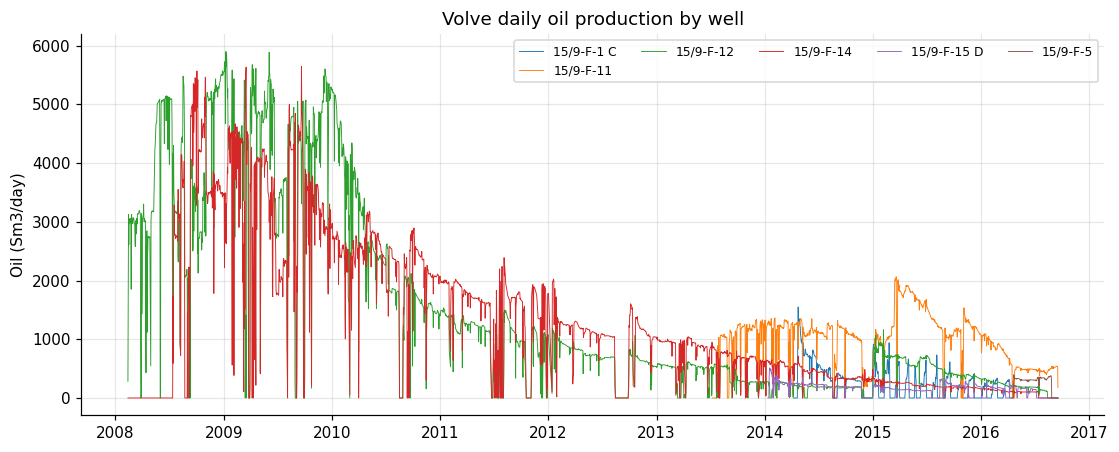

In [5]:
# 1b. Chart: daily oil production for every producer
prod_daily = raw[(raw["WELL_TYPE"] == "OP")].copy()
fig, ax = plt.subplots(figsize=(12, 4.5))
for well, g in prod_daily.groupby("well"):
    ax.plot(g["DATEPRD"], g["BORE_OIL_VOL"], lw=0.6, label=well)
ax.set_title("Volve daily oil production by well")
ax.set_ylabel("Oil (Sm3/day)")
ax.legend(ncol=5, fontsize=8, loc="upper right")
save(fig, "01_daily_oil_by_well.png"); plt.show()


- chart of water cut

Saved figure: outputs/figures/02_water_cut_by_well.png


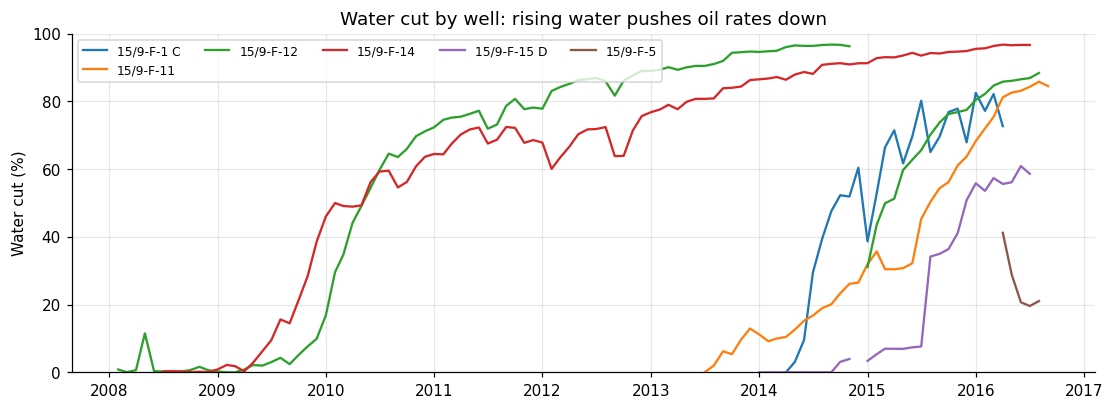

In [6]:
# 1c. Chart: water cut over time (water / (water + oil)), monthly
m = prod_daily.set_index("DATEPRD").groupby("well")[["BORE_OIL_VOL", "BORE_WAT_VOL"]].resample("MS").sum().reset_index()
m["water_cut"] = m["BORE_WAT_VOL"] / (m["BORE_WAT_VOL"] + m["BORE_OIL_VOL"])
fig, ax = plt.subplots(figsize=(12, 4))
for well, g in m.groupby("well"):
    ax.plot(g["DATEPRD"], g["water_cut"] * 100, lw=1.5, label=well)
ax.set_title("Water cut by well: rising water pushes oil rates down")
ax.set_ylabel("Water cut (%)"); ax.set_ylim(0, 100)
ax.legend(ncol=5, fontsize=8)
save(fig, "02_water_cut_by_well.png"); plt.show()

Step 4: Data Cleaning

- daily to weekly

In [7]:
# 2a. Daily -> weekly, per producer
d = raw[raw["WELL_TYPE"] == "OP"].copy()
d["ON_STREAM_HRS"] = d["ON_STREAM_HRS"].clip(0, 24).fillna(0)
for c in ["BORE_OIL_VOL", "BORE_WAT_VOL", "BORE_GAS_VOL"]:
    d[c] = d[c].fillna(0)
d = d[(d["ON_STREAM_HRS"] > 0) & (d["BORE_OIL_VOL"] > 0)]
for c in ["AVG_CHOKE_SIZE_P", "AVG_WHP_P"]:
    d[c] = d[c].where(d[c] > 0)          # zeros are gauge gaps, not real readings
d["week"] = d["DATEPRD"].dt.to_period("W-SUN").dt.start_time

frames = []
for well, g in d.groupby("well"):
    w = g.groupby("week").agg(oil=("BORE_OIL_VOL", "sum"), water=("BORE_WAT_VOL", "sum"),
                              gas=("BORE_GAS_VOL", "sum"), hours=("ON_STREAM_HRS", "sum"),
                              choke=("AVG_CHOKE_SIZE_P", "mean"), whp=("AVG_WHP_P", "mean"))
    w = w.reindex(pd.date_range(w.index.min(), w.index.max(), freq="W-MON"))   # no missing weeks
    w.index.name = "week"
    w["hours"] = w["hours"].fillna(0)
    w[["oil", "water", "gas"]] = w[["oil", "water", "gas"]].fillna(0)
    observed = w["hours"] >= 48                       # at least 2 producing days
    w["rate"] = (w["oil"] / (w["hours"] / 24)).where(observed)
    w["water_cut"] = (w["water"] / (w["water"] + w["oil"])).where(observed)
    w["on_frac"] = w["hours"] / 168
    w["well"] = well
    frames.append(w.reset_index())
weekly = pd.concat(frames, ignore_index=True)
weekly["log_rate"] = np.log(weekly["rate"])

# Filled versions used only as model INPUTS (targets always use the real, unfilled rate)
g = weekly.groupby("well")
weekly["log_rate_f"] = g["log_rate"].transform(lambda s: s.interpolate(limit_direction="both"))
weekly["water_cut_f"] = g["water_cut"].transform(lambda s: s.interpolate(limit_direction="both")).fillna(0)
weekly["choke_f"] = g["choke"].transform(lambda s: s.ffill().bfill())
weekly["whp_f"] = g["whp"].transform(lambda s: s.ffill().bfill())

weekly.to_csv(OUT / "weekly_production.csv", index=False)
summary = weekly.groupby("well").agg(first_week=("week", "min"), last_week=("week", "max"),
                                     weeks=("week", "count"), observed=("rate", "count"),
                                     peak_rate=("rate", "max"))
summary

,first_week,last_week,weeks,observed,peak_rate
well,,,,,
15/9-F-1 C,2014-04-21,2016-04-04,103,69,1215.296667
15/9-F-11,2013-07-22,2016-09-12,165,162,1902.961429
15/9-F-12,2008-02-11,2016-08-08,444,414,5646.580099
15/9-F-14,2008-07-07,2016-07-11,419,398,5215.076391
15/9-F-15 D,2014-01-13,2016-07-04,130,114,461.765000
15/9-F-5,2016-04-18,2016-08-22,19,18,376.975130


- detect restarts and interventions

In [8]:
# 2b. Detect rate step-ups (restarts / interventions)
STEP_UP = np.log(1.5)
def detect_events(f):
    lr = f["log_rate"]
    now = lr.rolling(4, min_periods=2).median()
    before = lr.shift(4).rolling(8, min_periods=4).median()
    flag = (now - before) > STEP_UP
    events, last = [], None
    for wk in f.loc[flag, "week"]:
        if last is None or (wk - last).days > 91:      # one event per 13-week cluster
            events.append(wk)
        last = wk
    return events

weekly["event"] = False
event_rows = []
for well, f in weekly.groupby("well"):
    for wk in detect_events(f):
        weekly.loc[(weekly["well"] == well) & (weekly["week"] == wk), "event"] = True
        event_rows.append({"well": well, "week": wk.date()})
g = weekly.groupby("well")
weekly["event_count"] = g["event"].cumsum()
weekly["weeks_since_event"] = 104.0                 # capped at 2 years
for well, f in weekly.groupby("well"):
    since, out = 104, []
    for e in f["event"]:
        since = 0 if e else min(since + 1, 104)
        out.append(since)
    weekly.loc[f.index, "weeks_since_event"] = out
weekly.to_csv(OUT / "weekly_production.csv", index=False)
pd.DataFrame(event_rows)

,well,week
0,15/9-F-1 C,2015-01-05
1,15/9-F-1 C,2015-08-17
2,15/9-F-11,2015-01-19
3,15/9-F-12,2008-05-26
4,15/9-F-12,2008-11-17
5,15/9-F-12,2015-01-05
6,15/9-F-14,2008-09-29
7,15/9-F-14,2009-08-17
8,15/9-F-15 D,2015-08-24


Stage 5: Backtest design

- wells to forecast and the backtest chart

Forecasting: ['15/9-F-1 C', '15/9-F-11', '15/9-F-12', '15/9-F-14', '15/9-F-15 D'] | skipped (too little history): ['15/9-F-5']
Saved figure: outputs/figures/03_backtest_design.png


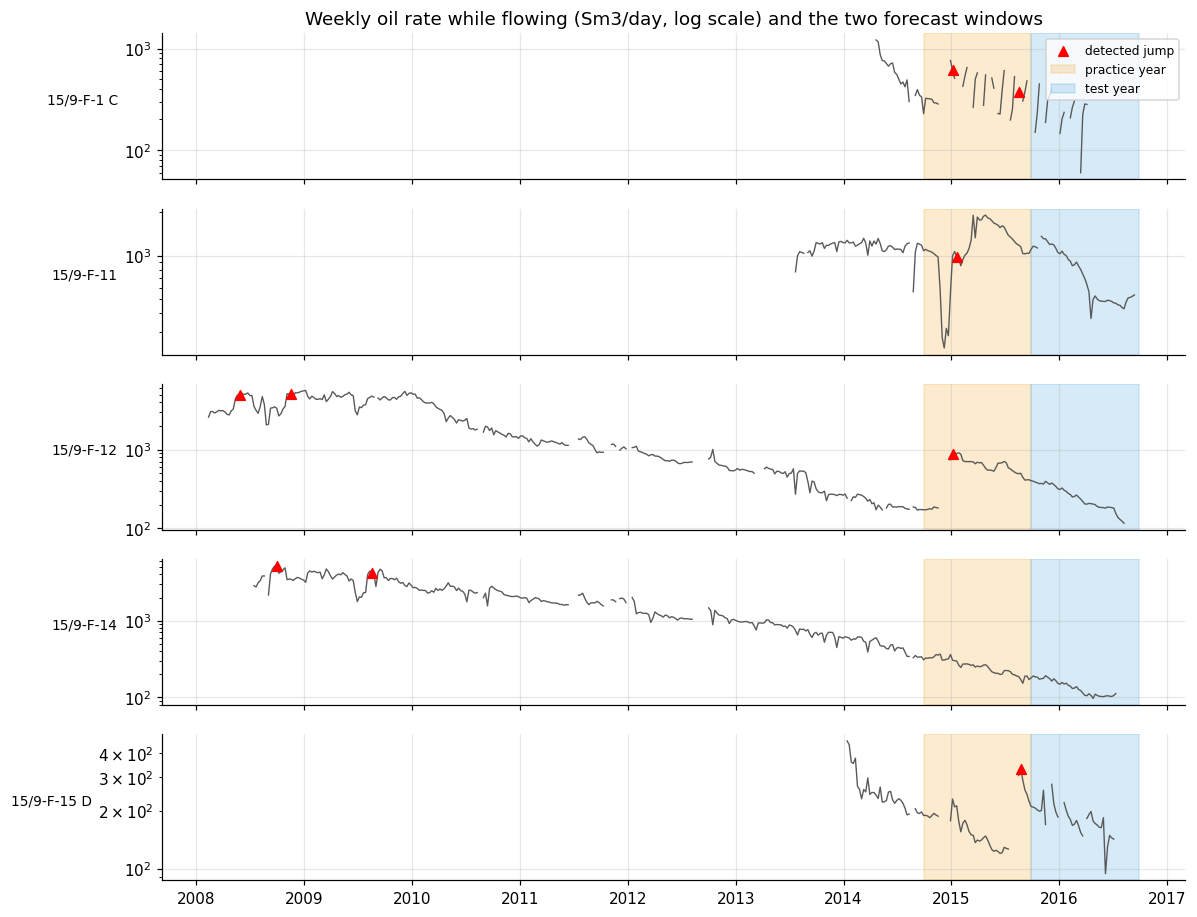

In [9]:
# 3a. Wells to forecast: producers with at least 26 observed weeks before the test date
obs_before = weekly[weekly["week"] < TEST_ORIGIN].groupby("well")["rate"].count()
wells = sorted(obs_before[obs_before >= 26].index)
print("Forecasting:", wells, "| skipped (too little history):", sorted(set(weekly["well"]) - set(wells)))

# Chart: the two forecast windows on each well's history
fig, axes = plt.subplots(len(wells), 1, figsize=(12, 2.0 * len(wells)), sharex=True)
for ax, well in zip(axes, wells):
    w = weekly[weekly["well"] == well]
    ax.plot(w["week"], w["rate"], color="0.35", lw=0.9)
    ev = w[w["event"]]
    ax.scatter(ev["week"], ev["rate"].fillna(w["rate"].median()), marker="^", color="red", s=40, zorder=3,
               label="detected jump" if well == wells[0] else None)
    ax.axvspan(VAL_ORIGIN, VAL_ORIGIN + pd.Timedelta(weeks=HORIZON), color="#F5B041", alpha=0.25, label="practice year")
    ax.axvspan(TEST_ORIGIN, TEST_ORIGIN + pd.Timedelta(weeks=HORIZON), color="#5DADE2", alpha=0.25, label="test year")
    ax.set_yscale("log"); ax.set_ylabel(well, rotation=0, ha="right", fontsize=9)
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title("Weekly oil rate while flowing (Sm3/day, log scale) and the two forecast windows")
save(fig, "03_backtest_design.png"); plt.show()

- helpers shared by every model

In [10]:
# 3b. Helpers shared by every model
def well_arrays(well):
    # One well's weekly series as plain numpy arrays (fast to slice).
    w = weekly[weekly["well"] == well].reset_index(drop=True)
    return {"week": w["week"].values, "lr": w["log_rate"].values, "lr_f": w["log_rate_f"].values,
            "wc": w["water_cut_f"].values, "on": w["on_frac"].values,
            "choke": w["choke_f"].values, "whp": w["whp_f"].values, "rate": w["rate"].values,
            "ev": w["event_count"].values.astype(int), "since": w["weeks_since_event"].values.astype(float)}

def jump_between(a, i, j):
    # True if a detected jump happens after week i and up to week j.
    return a["ev"][j] - a["ev"][i] > 0

def n_before(a, origin):
    # How many weeks of this well come before the forecast date.
    return int((a["week"] < np.datetime64(origin)).sum())

def forecast_frame(well, a, origin_idx, lo, mid, hi, method):
    # Put one well's forecast for the weeks after the origin into a tidy table.
    idx = np.arange(origin_idx + 1, origin_idx + 1 + len(mid))
    return pd.DataFrame({"well": well, "week": a["week"][idx], "h": idx - origin_idx,
                         "actual": a["rate"][idx], "lo": lo, "p50": mid, "hi": hi, "method": method,
                         "after_jump": a["ev"][idx] - a["ev"][origin_idx] > 0})

def future_len(a, i0):
    # Weeks available after origin index i0, capped at the horizon.
    return int(min(HORIZON, len(a["week"]) - (i0 + 1)))

ARRAYS = {w: well_arrays(w) for w in wells}
FORECASTS = {"val": {}, "test": {}}       # filled by Stages 4-6

Step 5: Model 1 - Arps decline curve

In [11]:
# 4a. Arps model
def arps_log(t, qi, di, b):
    return np.log(qi) - np.log1p(b * di * t) / b

def fit_arps(t, y_log):
    qmax = np.exp(y_log.max())
    p0 = [np.exp(np.median(y_log[:4])), 0.01, 0.5]
    bounds = ([0.2 * qmax, 1e-5, 1e-3], [5 * qmax, 0.5, 1.0])
    p0[0] = float(np.clip(p0[0], bounds[0][0] * 1.01, bounds[1][0] * 0.99))
    return curve_fit(arps_log, t, y_log, p0=p0, bounds=bounds, maxfev=20000)[0]

def arps_forecast(origin, n_boot=200, seed=0):
    rng = np.random.default_rng(seed)
    out, params = [], []
    for well, a in ARRAYS.items():
        i0 = n_before(a, origin) - 1
        if i0 < 12 or future_len(a, i0) < 1:
            continue
        hist_t = np.arange(i0 + 1)
        ok = ~np.isnan(a["lr"][: i0 + 1])
        t_obs, y_obs = hist_t[ok], a["lr"][: i0 + 1][ok]
        if len(t_obs) < 13:
            continue
        smooth = pd.Series(y_obs).rolling(5, center=True, min_periods=1).median().values
        recent = t_obs >= i0 - 104                                 # look at the last 2 years only
        start = t_obs[recent][np.argmax(smooth[recent])]           # fit from the smoothed peak in that window
        jumps = np.where(np.diff(a["ev"][: i0 + 1]) > 0)[0] + 1    # week indices of detected jumps
        last_jump = jumps[-1] if len(jumps) else -1
        recent_jump = bool(last_jump > start and (t_obs >= last_jump).sum() < 13)
        if last_jump > start and not recent_jump:
            start = last_jump                                      # 13+ weeks since the jump: fit from it
        sel = t_obs >= start
        if sel.sum() < 13:
            sel = t_obs >= t_obs[-13]
        tf, yf = t_obs[sel] - start, y_obs[sel]
        qi, di, b = fit_arps(tf, yf)
        resid = yf - arps_log(tf, qi, di, b)
        H = future_len(a, i0)
        t_fut = np.arange(i0 + 1, i0 + 1 + H) - start
        sims = []
        for _ in range(n_boot):
            try:
                p = fit_arps(tf, arps_log(tf, qi, di, b) + rng.choice(resid, len(resid)))
            except RuntimeError:
                continue
            sims.append(arps_log(t_fut, *p) + rng.choice(resid, H))
        sims = np.array(sims)
        mid = np.exp(arps_log(t_fut, qi, di, b))
        out.append(forecast_frame(well, a, i0, np.exp(np.percentile(sims, 10, 0)), mid,
                                  np.exp(np.percentile(sims, 90, 0)), "Arps decline"))
        params.append({"well": well, "qi_sm3d": qi, "Di_per_year": di * 52, "b": b, "weeks_fitted": int(sel.sum()),
                       "jump_under_13_weeks_before_forecast": recent_jump})
    return pd.concat(out, ignore_index=True), pd.DataFrame(params)

for run, origin in [("val", VAL_ORIGIN), ("test", TEST_ORIGIN)]:
    FORECASTS[run]["Arps decline"], arps_params = arps_forecast(origin)
print("Arps parameters for the TEST forecast. b near 0 = exponential decline (typical when water cut is rising);")
print("b = 1.0 = harmonic, the upper limit allowed. A b sitting on a limit is worth discussing in your findings.")
arps_params.round(3)

Arps parameters for the TEST forecast. b near 0 = exponential decline (typical when water cut is rising);
b = 1.0 = harmonic, the upper limit allowed. A b sitting on a limit is worth discussing in your findings.


,well,qi_sm3d,Di_per_year,b,weeks_fitted,jump_under_13_weeks_before_forecast
0,15/9-F-1 C,646.656,0.790,1.000,52,True
1,15/9-F-11,1996.392,1.506,0.001,24,False
2,15/9-F-12,831.892,0.864,0.001,37,False
3,15/9-F-14,671.195,0.717,0.001,97,False
4,15/9-F-15 D,302.229,0.665,1.000,78,True


Step 6: Model 2 - quantile gradient boosting

- feature engineering and training

In [12]:
# 6a. Features and training table
LAGS = 12

def gbm_state(a, i):
    # Describe well `a` at week index i. Returns (features without h, anchor).
    lr = a["lr_f"][i - LAGS + 1: i + 1]
    anchor = lr[-4:].mean()
    wc = a["wc"][i - LAGS + 1: i + 1]
    feats = list((lr[::-1] - anchor))                                   # lag0 .. lag11
    feats += [np.polyfit(np.arange(LAGS), lr, 1)[0],                    # 12-week trend
              wc[-4:].mean(), np.polyfit(np.arange(LAGS), wc, 1)[0],    # water cut level, trend
              np.nanmean(a["on"][i - 3: i + 1]),
              np.nanmean(a["choke"][i - 3: i + 1]) if not np.all(np.isnan(a["choke"][i - 3: i + 1])) else np.nan,
              np.nanmean(a["whp"][i - 3: i + 1]) if not np.all(np.isnan(a["whp"][i - 3: i + 1])) else np.nan,
              a["since"][i]]                                            # weeks since last jump
    return feats, anchor

GBM_COLS = [f"lag{k}" for k in range(LAGS)] + ["trend12", "water_cut", "water_cut_trend",
                                               "on_stream", "choke", "whp", "weeks_since_jump", "horizon"]

def gbm_training_table(origin):
    X, y = [], []
    for well, a in ARRAYS.items():
        n = n_before(a, origin)                       # only weeks before the forecast date
        for i in range(LAGS - 1, n - 1):
            feats, anchor = gbm_state(a, i)
            for h in range(1, HORIZON + 1):
                j = i + h
                if j >= n:
                    break
                if not np.isnan(a["lr"][j]) and not jump_between(a, i, j):   # real week, no jump in between
                    X.append(feats + [h]); y.append(a["lr"][j] - anchor)
    return pd.DataFrame(X, columns=GBM_COLS), np.array(y)

X_demo, y_demo = gbm_training_table(TEST_ORIGIN)
print(f"Test-run training table: {len(X_demo):,} examples x {X_demo.shape[1]} inputs")
X_demo.head()

Test-run training table: 35,183 examples x 20 inputs


,lag0,lag1,lag2,lag3,lag4,lag5,lag6,lag7,lag8,lag9,lag10,lag11,trend12,water_cut,water_cut_trend,on_stream,choke,whp,weeks_since_jump,horizon
0,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,1
1,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,2
2,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,3
3,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,4
4,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,5


- train and forecast

In [13]:
# 6b. Train and forecast
QUANTILES = {"lo": 0.10, "p50": 0.50, "hi": 0.90}

def gbm_forecast(origin, seed=0):
    X, y = gbm_training_table(origin)
    models = {k: HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=400,
                                               learning_rate=0.04, max_leaf_nodes=15,
                                               min_samples_leaf=40, l2_regularization=1.0,
                                               random_state=seed).fit(X, y)
              for k, q in QUANTILES.items()}
    out = []
    for well, a in ARRAYS.items():
        i0 = n_before(a, origin) - 1
        H = future_len(a, i0)
        if i0 < LAGS - 1 or H < 1:
            continue
        feats, anchor = gbm_state(a, i0)
        Xf = pd.DataFrame([feats + [h] for h in range(1, H + 1)], columns=GBM_COLS)
        pred = np.sort(np.vstack([models[k].predict(Xf) for k in ["lo", "p50", "hi"]]), axis=0)
        lo, mid, hi = np.exp(anchor + pred)
        out.append(forecast_frame(well, a, i0, lo, mid, hi, "Gradient boosting"))
    return pd.concat(out, ignore_index=True), models

for run, origin in [("val", VAL_ORIGIN), ("test", TEST_ORIGIN)]:
    t0 = time.time()
    FORECASTS[run]["Gradient boosting"], gbm_models = gbm_forecast(origin)
    print(f"{run}: trained and forecast in {time.time() - t0:.0f}s")

val: trained and forecast in 12s
test: trained and forecast in 14s


Step 7: Model 3 - Temporal Fusion Transformer

- PyTorch check

In [14]:
# 7a. PyTorch check (comes pre-installed in Colab)
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| running on", DEVICE)

PyTorch 2.11.0+cpu | running on cpu


- TFT building blocks and self-check

In [15]:
# 7b. TFT building blocks
class GLU(nn.Module):
    # Gated linear unit: a learned on/off switch for each feature.
    def __init__(self, d_in, d_out):
        super().__init__()
        self.fc = nn.Linear(d_in, 2 * d_out)
    def forward(self, x):
        return F.glu(self.fc(x), dim=-1)

class GRN(nn.Module):
    # Gated residual network, the basic TFT block.
    def __init__(self, d_in, d_hidden, d_out, d_context=None, dropout=0.1):
        super().__init__()
        self.skip = nn.Linear(d_in, d_out) if d_in != d_out else nn.Identity()
        self.fc1 = nn.Linear(d_in, d_hidden)
        self.ctx = nn.Linear(d_context, d_hidden, bias=False) if d_context else None
        self.fc2 = nn.Linear(d_hidden, d_hidden)
        self.drop = nn.Dropout(dropout)
        self.glu = GLU(d_hidden, d_out)
        self.norm = nn.LayerNorm(d_out)
    def forward(self, x, c=None):
        a = self.fc1(x)
        if self.ctx is not None and c is not None:
            if a.dim() == 3 and c.dim() == 2:
                c = c.unsqueeze(1)                     # same context for every time step
            a = a + self.ctx(c)
        a = self.drop(self.fc2(F.elu(a)))
        return self.norm(self.skip(x) + self.glu(a))

class VariableSelection(nn.Module):
    # Embeds each input separately, then learns a weight per input (sums to 1).
    def __init__(self, n_vars, d, dropout):
        super().__init__()
        self.n_vars = n_vars
        self.embed = nn.ModuleList([nn.Linear(1, d) for _ in range(n_vars)])
        self.weights_grn = GRN(n_vars * d, d, n_vars, d_context=d, dropout=dropout)
        self.var_grns = nn.ModuleList([GRN(d, d, d, dropout=dropout) for _ in range(n_vars)])
    def forward(self, x, c):                           # x: [batch, time, n_vars]
        emb = [self.embed[v](x[..., v:v + 1]) for v in range(self.n_vars)]
        w = torch.softmax(self.weights_grn(torch.cat(emb, -1), c), dim=-1)     # [B, T, V]
        processed = torch.stack([self.var_grns[v](emb[v]) for v in range(self.n_vars)], -1)  # [B, T, d, V]
        return (processed * w.unsqueeze(-2)).sum(-1), w

class InterpretableAttention(nn.Module):
    # Multi-head attention with a shared value projection, so head weights can be averaged and read.
    def __init__(self, d, n_heads, dropout):
        super().__init__()
        self.n_heads, self.dk = n_heads, d // n_heads
        self.q = nn.ModuleList([nn.Linear(d, self.dk) for _ in range(n_heads)])
        self.k = nn.ModuleList([nn.Linear(d, self.dk) for _ in range(n_heads)])
        self.v = nn.Linear(d, self.dk)
        self.out = nn.Linear(self.dk, d)
        self.drop = nn.Dropout(dropout)
    def forward(self, q, k, v, mask):                  # mask: True = not allowed to look
        v = self.v(v)
        heads, attn = [], []
        for h in range(self.n_heads):
            s = self.q[h](q) @ self.k[h](k).transpose(1, 2) / math.sqrt(self.dk)
            a = self.drop(torch.softmax(s.masked_fill(mask, -1e9), dim=-1))
            heads.append(a @ v); attn.append(a)
        return self.out(torch.stack(heads).mean(0)), torch.stack(attn).mean(0)

class TFT(nn.Module):
    def __init__(self, n_past, n_future, n_wells, d=32, n_heads=4, dropout=0.1, n_quantiles=3):
        super().__init__()
        self.well_emb = nn.Embedding(n_wells, d)
        self.static = nn.ModuleList([GRN(d, d, d, dropout=dropout) for _ in range(4)])
        self.vsn_past = VariableSelection(n_past, d, dropout)
        self.vsn_future = VariableSelection(n_future, d, dropout)
        self.lstm_enc = nn.LSTM(d, d, batch_first=True)
        self.lstm_dec = nn.LSTM(d, d, batch_first=True)
        self.gate1, self.norm1 = GLU(d, d), nn.LayerNorm(d)
        self.enrich = GRN(d, d, d, d_context=d, dropout=dropout)
        self.attn = InterpretableAttention(d, n_heads, dropout)
        self.gate2, self.norm2 = GLU(d, d), nn.LayerNorm(d)
        self.ff = GRN(d, d, d, dropout=dropout)
        self.gate3, self.norm3 = GLU(d, d), nn.LayerNorm(d)
        self.head = nn.Linear(d, n_quantiles)

    def forward(self, x_past, x_future, well):
        s = self.well_emb(well)
        c_select, c_enrich, c_h, c_c = [g(s) for g in self.static]
        past, w_past = self.vsn_past(x_past, c_select)
        fut, w_fut = self.vsn_future(x_future, c_select)
        enc, state = self.lstm_enc(past, (c_h.unsqueeze(0).contiguous(), c_c.unsqueeze(0).contiguous()))
        dec, _ = self.lstm_dec(fut, state)
        temporal = self.norm1(torch.cat([past, fut], 1) + self.gate1(torch.cat([enc, dec], 1)))
        enriched = self.enrich(temporal, c_enrich)
        T_enc, T = x_past.shape[1], enriched.shape[1]
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x_past.device), diagonal=1)[T_enc:]
        att, att_w = self.attn(enriched[:, T_enc:], enriched, enriched, mask)
        x = self.norm2(enriched[:, T_enc:] + self.gate2(att))
        x = self.norm3(temporal[:, T_enc:] + self.gate3(self.ff(x)))
        return self.head(x), w_past, att_w

def quantile_loss(pred, y, mask, qs):
    e = y.unsqueeze(-1) - pred
    loss = torch.maximum(qs * e, (qs - 1) * e).sum(-1)
    return (loss * mask).sum() / mask.sum().clamp(min=1)

# Self-check on random numbers: catches set-up problems in seconds
_m = TFT(n_past=8, n_future=1, n_wells=5).to(DEVICE)
_p, _w, _a = _m(torch.randn(2, 26, 8, device=DEVICE), torch.randn(2, 52, 1, device=DEVICE),
                torch.tensor([0, 1], device=DEVICE))
assert _p.shape == (2, 52, 3) and _w.shape == (2, 26, 8) and _a.shape == (2, 52, 78), (_p.shape, _w.shape, _a.shape)
print(f"TFT self-check passed: {sum(p.numel() for p in _m.parameters()):,} parameters")

TFT self-check passed: 108,408 parameters


- build the TFT training samples

In [16]:
# 7c. Turn the weekly table into TFT training samples
ENC = 26                                          # weeks of history the TFT reads
PAST_VARS = ["log-rate (vs anchor)", "observed week", "water cut", "time on stream",
             "choke", "wellhead pressure", "weeks since jump", "relative time"]
WELL_ID = {w: k for k, w in enumerate(wells)}

def tft_inputs(origin):
    # Scale choke and WHP with statistics from BEFORE the forecast date only.
    pre = weekly[weekly["week"] < origin]
    stats = {c: (pre[c].mean(), pre[c].std() + 1e-6) for c in ["choke_f", "whp_f"]}
    feats = {}
    for well, a in ARRAYS.items():
        ch = np.nan_to_num((a["choke"] - stats["choke_f"][0]) / stats["choke_f"][1])
        wh = np.nan_to_num((a["whp"] - stats["whp_f"][0]) / stats["whp_f"][1])
        feats[well] = np.column_stack([a["lr_f"], (~np.isnan(a["lr"])).astype(float), a["wc"], a["on"], ch, wh,
                                       a["since"] / 104])
    return feats

def tft_sample(well, a, f, i, n):
    # One sample at origin index i; targets only for weeks before index n (the forecast date).
    anchor = a["lr_f"][i - 3: i + 1].mean()
    past = f[i - ENC + 1: i + 1].copy()
    past[:, 0] -= anchor
    rel_past = (np.arange(i - ENC + 1, i + 1) - i) / HORIZON
    x_past = np.column_stack([past, rel_past])
    x_fut = (np.arange(1, HORIZON + 1) / HORIZON)[:, None]
    y, m = np.zeros(HORIZON), np.zeros(HORIZON)
    for h in range(1, HORIZON + 1):
        j = i + h
        if j < n and not np.isnan(a["lr"][j]) and not jump_between(a, i, j):
            y[h - 1], m[h - 1] = a["lr"][j] - anchor, 1.0
    return x_past, x_fut, y, m, anchor

def tft_dataset(origin):
    f_all = tft_inputs(origin)
    XP, XF, Y, M, W = [], [], [], [], []
    for well, a in ARRAYS.items():
        n = n_before(a, origin)
        for i in range(ENC - 1, n - 1):
            xp, xf, y, m, _ = tft_sample(well, a, f_all[well], i, n)
            if m.sum() > 0:
                XP.append(xp); XF.append(xf); Y.append(y); M.append(m); W.append(WELL_ID[well])
    t = lambda z, dt=torch.float32: torch.tensor(np.array(z), dtype=dt)
    return t(XP), t(XF), t(Y), t(M), t(W, torch.long), f_all

XP, XF, Y, M, W, _ = tft_dataset(TEST_ORIGIN)
print(f"Test-run TFT training samples: {len(XP)}  | past window {tuple(XP.shape[1:])} | future {tuple(XF.shape[1:])}")

Test-run TFT training samples: 914  | past window (26, 8) | future (52, 1)


- train the TFT and forecast

In [17]:
# 7d. Train and forecast
def train_tft(XP, XF, Y, M, W, seed, epochs=60, batch=64, lr=2e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    model = TFT(n_past=XP.shape[-1], n_future=XF.shape[-1], n_wells=len(wells)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    qs = torch.tensor([0.1, 0.5, 0.9], device=DEVICE)
    data = [z.to(DEVICE) for z in (XP, XF, Y, M, W)]
    n = len(XP)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        total = 0.0
        for s in range(0, n, batch):
            b = perm[s:s + batch]
            pred, _, _ = model(data[0][b], data[1][b], data[4][b])
            loss = quantile_loss(pred, data[2][b], data[3][b], qs)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); total += loss.item() * len(b)
        sched.step()
        if ep % 20 == 0 or ep == epochs - 1:
            print(f"  seed {seed} epoch {ep:3d}  quantile loss {total / n:.4f}")
    return model.eval()

def tft_forecast(origin, seeds=(0, 1, 2)):
    XP, XF, Y, M, W, f_all = tft_dataset(origin)
    models = [train_tft(XP, XF, Y, M, W, seed) for seed in seeds]
    out, var_w = [], []
    for well, a in ARRAYS.items():
        n = n_before(a, origin); i0 = n - 1
        H = future_len(a, i0)
        if i0 < ENC - 1 or H < 1:
            continue
        xp, xf, _, _, anchor = tft_sample(well, a, f_all[well], i0, n)
        xp_t = torch.tensor(xp[None], dtype=torch.float32, device=DEVICE)
        xf_t = torch.tensor(xf[None], dtype=torch.float32, device=DEVICE)
        w_t = torch.tensor([WELL_ID[well]], device=DEVICE)
        with torch.no_grad():
            runs = [m(xp_t, xf_t, w_t) for m in models]
        pred = np.mean([r[0][0].cpu().numpy() for r in runs], axis=0)[:H]     # [H, 3]
        var_w.append(np.mean([r[1][0].mean(0).cpu().numpy() for r in runs], axis=0))
        lo, mid, hi = np.exp(anchor + np.sort(pred, axis=1)).T
        out.append(forecast_frame(well, a, i0, lo, mid, hi, "TFT"))
    importance = pd.Series(np.mean(var_w, axis=0), index=PAST_VARS).sort_values()
    return pd.concat(out, ignore_index=True), importance

for run, origin in [("val", VAL_ORIGIN), ("test", TEST_ORIGIN)]:
    t0 = time.time(); print(f"Training TFT for the {run} run ...")
    FORECASTS[run]["TFT"], tft_importance = tft_forecast(origin)
    print(f"{run}: done in {time.time() - t0:.0f}s")

Training TFT for the val run ...
  seed 0 epoch   0  quantile loss 0.1944
  seed 0 epoch  20  quantile loss 0.0971
  seed 0 epoch  40  quantile loss 0.0803
  seed 0 epoch  59  quantile loss 0.0773
  seed 1 epoch   0  quantile loss 0.2727
  seed 1 epoch  20  quantile loss 0.1084
  seed 1 epoch  40  quantile loss 0.0890
  seed 1 epoch  59  quantile loss 0.0858
  seed 2 epoch   0  quantile loss 0.3958
  seed 2 epoch  20  quantile loss 0.1085
  seed 2 epoch  40  quantile loss 0.0891
  seed 2 epoch  59  quantile loss 0.0863
val: done in 362s
Training TFT for the test run ...
  seed 0 epoch   0  quantile loss 0.2010
  seed 0 epoch  20  quantile loss 0.1082
  seed 0 epoch  40  quantile loss 0.0895
  seed 0 epoch  59  quantile loss 0.0866
  seed 1 epoch   0  quantile loss 0.2572
  seed 1 epoch  20  quantile loss 0.1093
  seed 1 epoch  40  quantile loss 0.0931
  seed 1 epoch  59  quantile loss 0.0900
  seed 2 epoch   0  quantile loss 0.3556
  seed 2 epoch  20  quantile loss 0.1109
  seed 2 epoc

Step 8: Calibrate the bands on the practice year


- Conformal Calibration

In [18]:
# 8a. Conformal calibration, one adjustment per method
def conformal_margin(df, target=0.80):
    ok = df["actual"].notna() & ~df["after_jump"]          # skip weeks after an in-window jump
    y, lo, hi = np.log(df.loc[ok, "actual"]), np.log(df.loc[ok, "lo"]), np.log(df.loc[ok, "hi"])
    scores = np.maximum(lo - y, y - hi).values          # >0 means outside the band
    n = len(scores)
    return float(np.quantile(scores, min(1.0, np.ceil((n + 1) * target) / n))), n

MARGINS = {}
for method, df in FORECASTS["val"].items():
    MARGINS[method], n = conformal_margin(df)
    print(f"{method:18s} practice-year weeks: {n:4d}   band adjustment (log units): {MARGINS[method]:+.3f}")

for method, df in FORECASTS["test"].items():
    df["lo_cal"] = df["lo"] * np.exp(-MARGINS[method])
    df["hi_cal"] = df["hi"] * np.exp(MARGINS[method])

Arps decline       practice-year weeks:  124   band adjustment (log units): +0.055
Gradient boosting  practice-year weeks:  124   band adjustment (log units): +0.156
TFT                practice-year weeks:  115   band adjustment (log units): +0.102


Step 9: Score the test year and draw the charts

- scores for all wells together

In [19]:
# 9a. Scores per well and for all wells together
def scores(g):
    g = g[g["actual"].notna() & ~g["after_jump"]]
    a = g["actual"]
    return pd.Series({
        "weeks": len(g),
        "MAPE_%": (abs(g["p50"] - a) / a).mean() * 100,
        "cum_error_%": (g["p50"].sum() - a.sum()) / a.sum() * 100,
        "coverage_raw_%": ((a >= g["lo"]) & (a <= g["hi"])).mean() * 100,
        "coverage_cal_%": ((a >= g["lo_cal"]) & (a <= g["hi_cal"])).mean() * 100,
        "band_width_x": (g["hi_cal"] / g["lo_cal"]).mean(),
    })

test = pd.concat(FORECASTS["test"].values(), ignore_index=True)
METHODS = [m for m in COLORS if m in FORECASTS["test"]]
per_well = pd.DataFrame({(m, w): scores(g) for (m, w), g in test.groupby(["method", "well"])}).T
overall = pd.DataFrame({m: scores(g) for m, g in test.groupby("method")}).T.loc[METHODS]
per_well.index.names = ["method", "well"]
per_well.round(1).to_csv(OUT / "metrics_per_well.csv"); overall.round(1).to_csv(OUT / "metrics_overall.csv")
print("=== All wells together (test year) ===")
overall.round(1)

=== All wells together (test year) ===


,weeks,MAPE_%,cum_error_%,coverage_raw_%,coverage_cal_%,band_width_x
Arps decline,191.0,26.7,-18.1,45.0,58.1,1.8
Gradient boosting,191.0,40.4,22.9,56.0,74.3,2.3
TFT,191.0,44.3,39.3,52.4,65.4,2.0


- scores per well

In [20]:
per_well.round(1)

weeks  MAPE_%  cum_error_%  coverage_raw_%  \
method            well                                                      
Arps decline      15/9-F-1 C    17.0    47.9          9.4            82.4   
                  15/9-F-11     50.0    33.5        -33.3            34.0   
                  15/9-F-12     46.0    26.7         21.2            21.7   
                  15/9-F-14     42.0     7.2         -3.3            81.0   
                  15/9-F-15 D   36.0    30.1        -30.7            30.6   
Gradient boosting 15/9-F-1 C    17.0    64.1         30.4            76.5   
                  15/9-F-11     50.0    42.2         16.8            50.0   
                  15/9-F-12     46.0    61.6         45.3            28.3   
                  15/9-F-14     42.0     7.4          0.5            50.0   
                  15/9-F-15 D   36.0    38.2         33.1            97.2   
TFT               15/9-F-1 C    17.0    54.7         21.8            88.2   
                  15/9-F-11     50.0    72.5         51.8            48.0   
                  15/9-F-12     46.0    69.4         52.8            19.6   
                  15/9-F-14     42.0     6.9         -4.3            78.6   
                  15/9-F-15 D   36.0    12.0         -9.6            52.8   

                               coverage_cal_%  band_width_x  
method            well                                       
Arps decline      15/9-F-1 C             82.4           3.1  
                  15/9-F-11              38.0           1.6  
                  15/9-F-12              39.1           1.6  
                  15/9-F-14              97.6           1.4  
                  15/9-F-15 D            52.8           1.9  
Gradient boosting 15/9-F-1 C             82.4           2.7  
                  15/9-F-11              64.0           2.3  
                  15/9-F-12              43.5           2.2  
                  15/9-F-14              97.6           1.5  
                  15/9-F-15 D            97.2           3.2  
TFT               15/9-F-1 C             88.2           4.1  
                  15/9-F-11              52.0           2.3  
                  15/9-F-12              28.3           1.6  
                  15/9-F-14             100.0           1.5  
                  15/9-F-15 D            80.6           1.5

- forecast grid chart

Saved figure: outputs/figures/04_forecast_grid.png


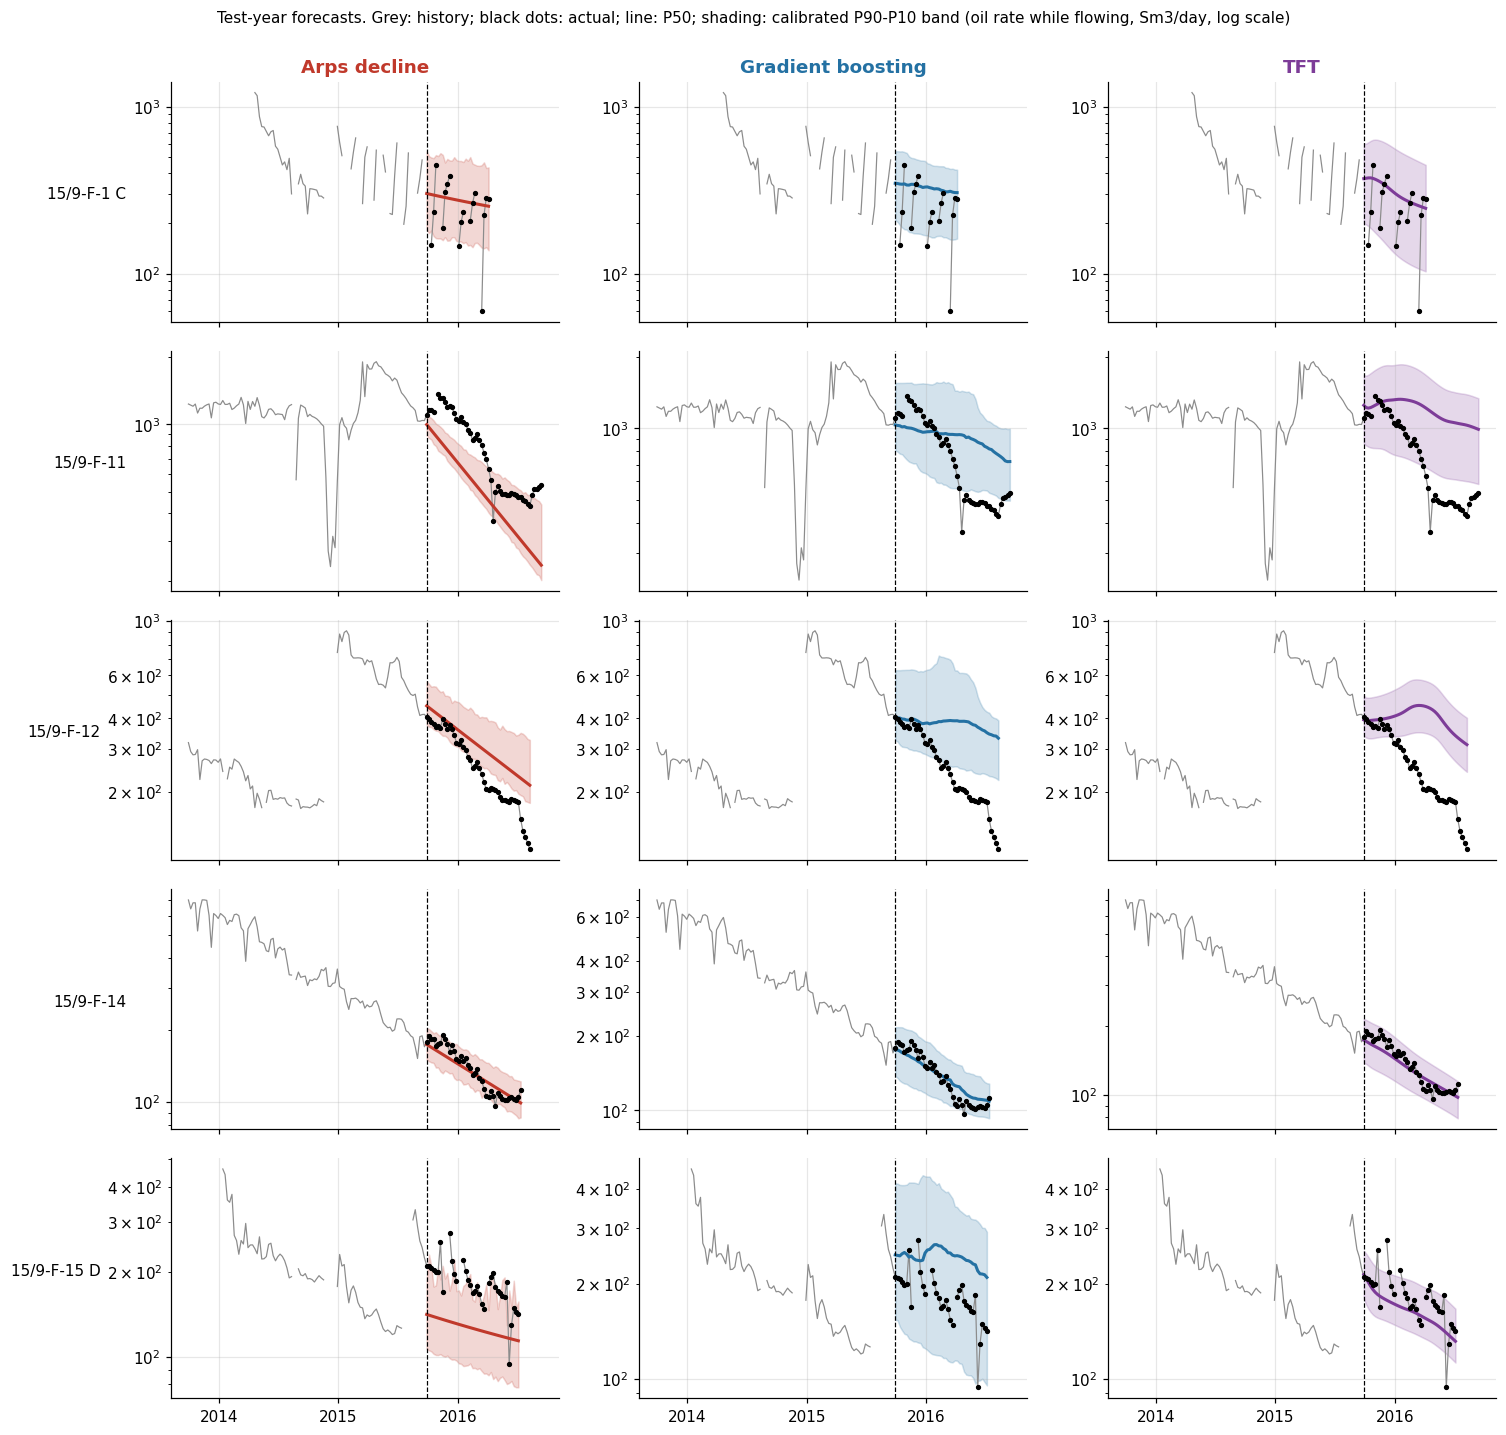

In [21]:
# 9b. Chart: every well x every method (history, actual test year, P50 and calibrated band)
hist_from = TEST_ORIGIN - pd.Timedelta(weeks=104)
fig, axes = plt.subplots(len(wells), len(METHODS), figsize=(4.6 * len(METHODS), 2.6 * len(wells)),
                         sharex=True, squeeze=False)
for r, well in enumerate(wells):
    w = weekly[(weekly["well"] == well) & (weekly["week"] >= hist_from)]
    for c, method in enumerate(METHODS):
        ax = axes[r, c]
        f = test[(test["well"] == well) & (test["method"] == method)]
        ax.plot(w["week"], w["rate"], color="0.55", lw=0.8)
        ax.scatter(f["week"], f["actual"], s=6, color="black", zorder=3)
        ax.fill_between(f["week"], f["lo_cal"], f["hi_cal"], color=COLORS[method], alpha=0.2)
        ax.plot(f["week"], f["p50"], color=COLORS[method], lw=2)
        ax.axvline(TEST_ORIGIN, color="k", ls="--", lw=0.8)
        ax.set_yscale("log")
        if r == 0: ax.set_title(method, color=COLORS[method], fontweight="bold")
        if c == 0: ax.set_ylabel(well, rotation=0, ha="right")
        ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Test-year forecasts. Grey: history; black dots: actual; line: P50; shading: calibrated P90-P10 band "
             "(oil rate while flowing, Sm3/day, log scale)", y=1.0, fontsize=10)
fig.tight_layout()
save(fig, "04_forecast_grid.png"); plt.show()

- scores chart

Saved figure: outputs/figures/05_scores.png


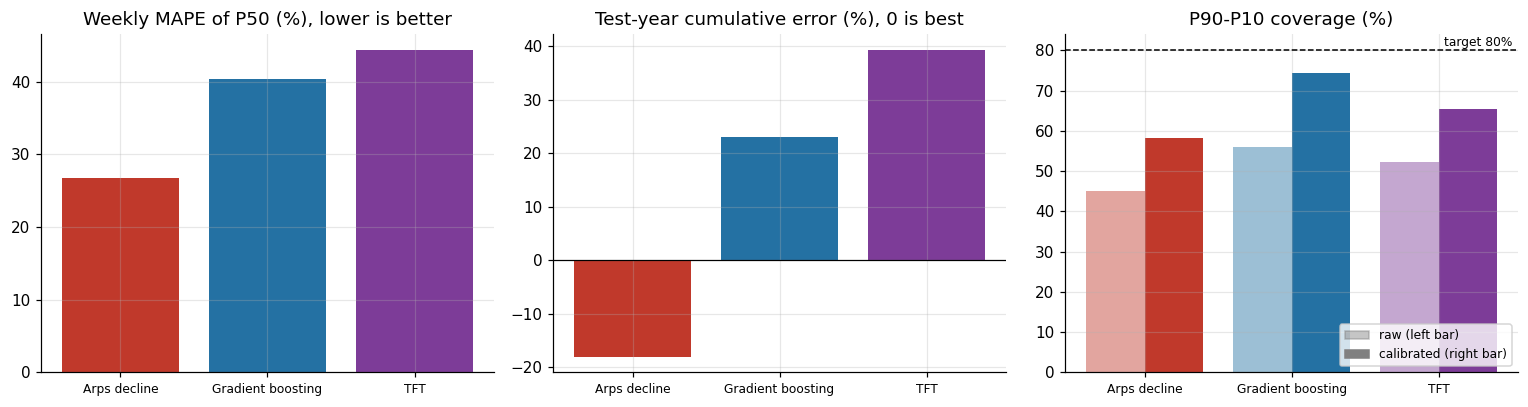

In [22]:
# 9c. Chart: scores side by side
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
cols = [COLORS[m] for m in METHODS]
axes[0].bar(METHODS, overall["MAPE_%"], color=cols); axes[0].set_title("Weekly MAPE of P50 (%), lower is better")
axes[1].bar(METHODS, overall["cum_error_%"], color=cols); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Test-year cumulative error (%), 0 is best")
x = np.arange(len(METHODS))
axes[2].bar(x - 0.2, overall["coverage_raw_%"], 0.4, color=cols, alpha=0.45, label="raw")
axes[2].bar(x + 0.2, overall["coverage_cal_%"], 0.4, color=cols, label="calibrated")
axes[2].axhline(80, color="k", ls="--", lw=1); axes[2].text(len(METHODS) - 0.5, 81, "target 80%", ha="right", fontsize=8)
from matplotlib.patches import Patch
axes[2].set_xticks(x, METHODS); axes[2].set_title("P90-P10 coverage (%)")
axes[2].legend(handles=[Patch(color="0.5", alpha=0.45, label="raw (left bar)"),
                        Patch(color="0.5", label="calibrated (right bar)")], fontsize=8, loc="lower right")
for ax in axes: ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); save(fig, "05_scores.png"); plt.show()

- error by forecast horizon

Saved figure: outputs/figures/06_error_by_horizon.png


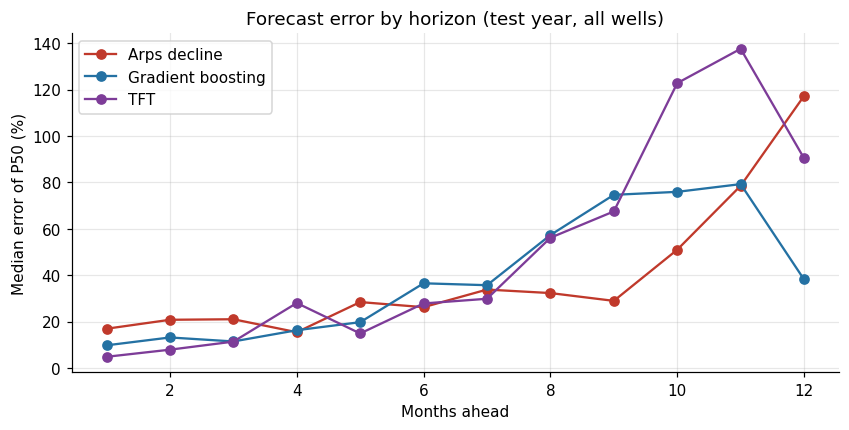

In [23]:
# 9d. Chart: how error grows with forecast horizon
test["abs_log_err"] = np.abs(np.log(test["p50"]) - np.log(test["actual"]))
test["month_ahead"] = ((test["h"] - 1) // 4.35).astype(int) + 1
fig, ax = plt.subplots(figsize=(9, 4))
for method in METHODS:
    e = test[test["method"] == method].groupby("month_ahead")["abs_log_err"].median()
    ax.plot(e.index, (np.exp(e.values) - 1) * 100, marker="o", color=COLORS[method], label=method)
ax.set_xlabel("Months ahead"); ax.set_ylabel("Median error of P50 (%)")
ax.set_title("Forecast error by horizon (test year, all wells)"); ax.legend()
save(fig, "06_error_by_horizon.png"); plt.show()

- field total

Saved figure: outputs/figures/07_field_total.png


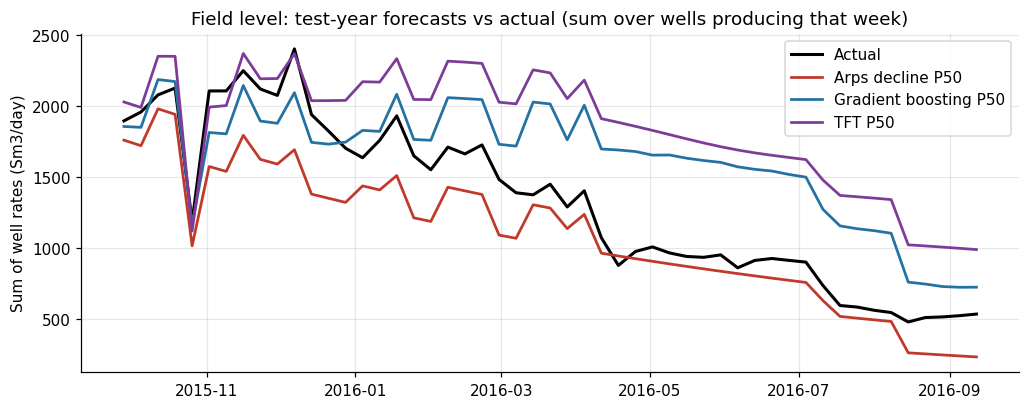

In [24]:
# 9e. Chart: field total (sum of the wells' rates) - actual vs each method's P50
ok = test[test["actual"].notna() & ~test["after_jump"]]
fig, ax = plt.subplots(figsize=(11, 4))
field_actual = ok[ok["method"] == METHODS[0]].groupby("week")["actual"].sum()
ax.plot(field_actual.index, field_actual.values, color="black", lw=2, label="Actual")
for method in METHODS:
    s = ok[ok["method"] == method].groupby("week")["p50"].sum()
    ax.plot(s.index, s.values, color=COLORS[method], lw=1.8, label=f"{method} P50")
ax.set_ylabel("Sum of well rates (Sm3/day)")
ax.set_title("Field level: test-year forecasts vs actual (sum over wells producing that week)")
ax.legend(); save(fig, "07_field_total.png"); plt.show()

- what TFT paid attention to

Saved figure: outputs/figures/08_tft_variable_importance.png


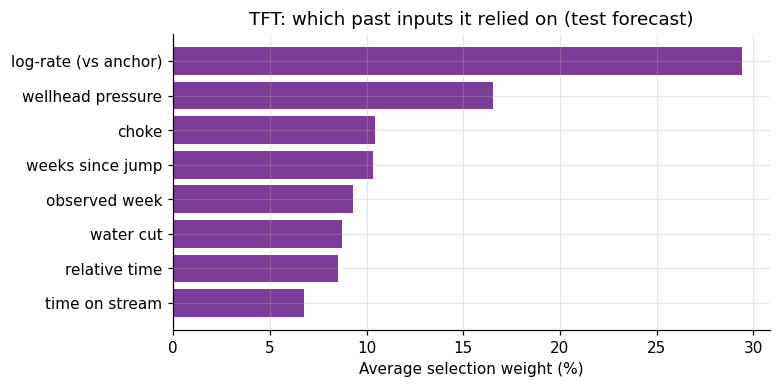

In [25]:
# 9f. Chart: what the TFT paid attention to (variable selection weights)
if "TFT" in FORECASTS["test"]:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(tft_importance.index, tft_importance.values * 100, color=COLORS["TFT"])
    ax.set_xlabel("Average selection weight (%)")
    ax.set_title("TFT: which past inputs it relied on (test forecast)")
    save(fig, "08_tft_variable_importance.png"); plt.show()

- Arps parameters per well

Saved figure: outputs/figures/09_arps_parameters.png


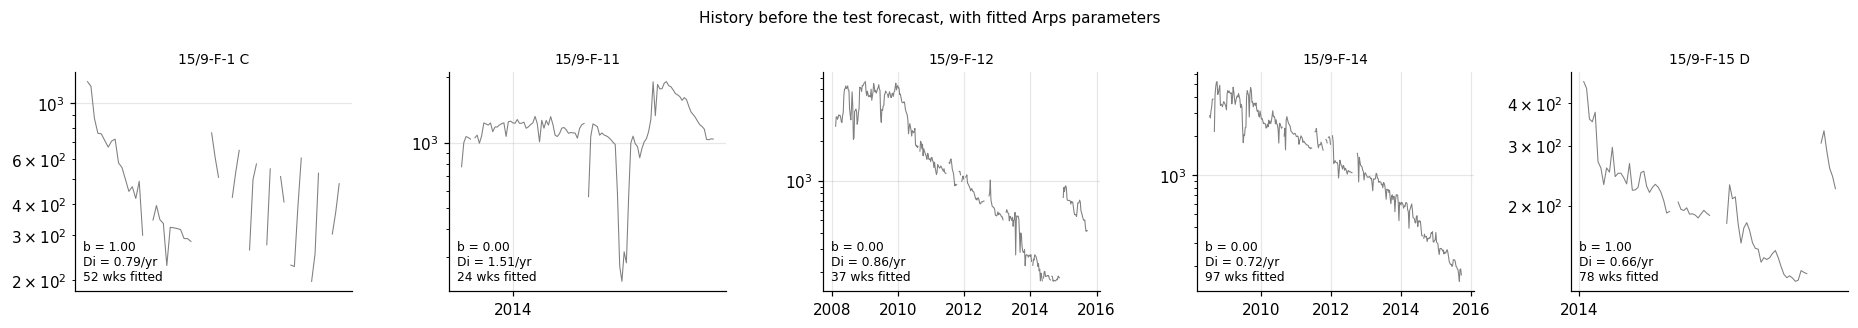

In [26]:
# 9g. Chart: Arps fit window and parameters, one panel per well (test run)
fig, axes = plt.subplots(1, len(wells), figsize=(3.4 * len(wells), 3), sharey=False)
for ax, (_, p) in zip(axes, arps_params.iterrows()):
    w = weekly[(weekly["well"] == p["well"]) & (weekly["week"] < TEST_ORIGIN)]
    ax.plot(w["week"], w["rate"], color="0.5", lw=0.7)
    ax.set_yscale("log"); ax.set_title(p["well"], fontsize=9)
    ax.text(0.03, 0.05, f"b = {p['b']:.2f}\nDi = {p['Di_per_year']:.2f}/yr\n{p['weeks_fitted']} wks fitted",
            transform=ax.transAxes, fontsize=8)
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("History before the test forecast, with fitted Arps parameters", fontsize=10)
fig.tight_layout(); save(fig, "09_arps_parameters.png"); plt.show()

Step 10: Save results

In [27]:
test.to_csv(OUT / "test_forecasts.csv", index=False)
pd.concat(FORECASTS["val"].values()).to_csv(OUT / "practice_year_forecasts.csv", index=False)
arps_params.to_csv(OUT / "arps_parameters.csv", index=False)

best_cum = overall["cum_error_%"].abs().idxmin()
best_mape = overall["MAPE_%"].idxmin()
lines = ["## Results: test year (forecast from 28 Sep 2015, 52 weeks)", "",
         "| Method | Weekly MAPE | Cumulative error | Coverage raw | Coverage calibrated |",
         "|---|---|---|---|---|"]
for m, r in overall.iterrows():
    lines.append(f"| {m} | {r['MAPE_%']:.1f}% | {r['cum_error_%']:+.1f}% | {r['coverage_raw_%']:.0f}% | {r['coverage_cal_%']:.0f}% |")
lines += ["", f"- Lowest cumulative error: **{best_cum}**", f"- Lowest weekly MAPE: **{best_mape}**",
          "- Coverage target for a P90-P10 band: 80%", ""]
(OUT / "results_summary.md").write_text("\n".join(lines))
print("\n".join(lines))
print("All outputs are in", OUT)

## Results: test year (forecast from 28 Sep 2015, 52 weeks)

| Method | Weekly MAPE | Cumulative error | Coverage raw | Coverage calibrated |
|---|---|---|---|---|
| Arps decline | 26.7% | -18.1% | 45% | 58% |
| Gradient boosting | 40.4% | +22.9% | 56% | 74% |
| TFT | 44.3% | +39.3% | 52% | 65% |

- Lowest cumulative error: **Arps decline**
- Lowest weekly MAPE: **Arps decline**
- Coverage target for a P90-P10 band: 80%

All outputs are in /content/drive/MyDrive/volve-forecasting/outputs


Step 11: Further evaluation metrics and models  comparison benchamarks


In [28]:
# 11a. Better scorecard + is the difference real?
from scipy.stats import binomtest

def naive_forecast(origin):
    # Simplest possible forecast: hold the last 4-week average rate flat for 52 weeks.
    out = []
    for well, a in ARRAYS.items():
        i0 = n_before(a, origin) - 1
        H = future_len(a, i0)
        if i0 < 3 or H < 1:
            continue
        level = np.full(H, np.exp(a["lr_f"][i0 - 3: i0 + 1].mean()))
        out.append(forecast_frame(well, a, i0, level, level, level, "Naive (flat)"))
    return pd.concat(out, ignore_index=True)

ok = test[test["actual"].notna() & ~test["after_jump"]].copy()
naive = naive_forecast(TEST_ORIGIN)
naive = naive[naive["actual"].notna() & ~naive["after_jump"]].copy()
naive["lo_cal"], naive["hi_cal"] = naive["lo"], naive["hi"]
naive_p50 = naive.set_index(["well", "week"])["p50"]
Q = np.array([0.1, 0.5, 0.9])

def scorecard_row(g):
    a, p = g["actual"].values, g["p50"].values
    la, lp = np.log(a), np.log(p)
    nb = naive_p50.loc[list(zip(g["well"], g["week"]))].values
    log_err, log_err_naive = np.abs(lp - la), np.abs(np.log(nb) - la)
    qs = np.log(np.column_stack([g["lo"], g["p50"], g["hi"]]))
    e = la[:, None] - qs
    lo, hi, alpha = np.log(g["lo_cal"].values), np.log(g["hi_cal"].values), 0.2
    return pd.Series({
        "WAPE_%": np.abs(p - a).sum() / a.sum() * 100,                      # volume-weighted error
        "bias_%": (p.sum() - a.sum()) / a.sum() * 100,                      # + over-forecast, - under
        "median_log_err_%": (np.exp(np.median(log_err)) - 1) * 100,         # typical miss, symmetric
        "skill_vs_naive_%": (1 - log_err.mean() / log_err_naive.mean()) * 100,  # >0 beats flat forecast
        "pinball_loss": np.maximum(Q * e, (Q - 1) * e).mean(),              # P90/P50/P10 quality (lower better)
        "interval_score": ((hi - lo) + 2 / alpha * np.maximum(lo - la, 0)
                           + 2 / alpha * np.maximum(la - hi, 0)).mean(),    # band width + misses (lower better)
    })

scorecard = pd.DataFrame({m: scorecard_row(ok[ok["method"] == m]) for m in METHODS})
scorecard["Naive (flat)"] = scorecard_row(naive)
scorecard = scorecard.T
scorecard.round(3).to_csv(OUT / "scorecard.csv")
print("=== Scorecard, test year (lower is better except skill_vs_naive) ===")
print(scorecard.round(2).to_string())

# Is ML really better or worse than Arps? Compare well by well (the honest unit with 5 wells)
err = (ok.assign(err=np.abs(np.log(ok["p50"]) - np.log(ok["actual"])))
         .groupby(["method", "well"])["err"].mean().unstack(0))
rng = np.random.default_rng(0)
print("\n=== Well-by-well comparison against Arps (mean absolute log error) ===")
for m in [x for x in METHODS if x != "Arps decline"]:
    d = (err[m] - err["Arps decline"]).dropna().values          # > 0 means ML was worse on that well
    boots = [rng.choice(d, len(d)).mean() for _ in range(5000)]
    lo_ci, hi_ci = np.percentile(boots, [2.5, 97.5])
    wins = int((d < 0).sum())
    p = binomtest(wins, len(d), 0.5).pvalue
    print(f"{m:18s} better on {wins} of {len(d)} wells | mean difference {d.mean():+.3f} "
          f"(95% CI {lo_ci:+.3f} to {hi_ci:+.3f}) | sign-test p = {p:.2f}")
print("\nNote: with 5 wells, even winning on all 5 gives p = 0.06, so this test cannot show significance at 5%.")
err.round(3)

=== Scorecard, test year (lower is better except skill_vs_naive) ===
                   WAPE_%  bias_%  median_log_err_%  skill_vs_naive_%  pinball_loss  interval_score
Arps decline        28.69  -18.09             28.68             32.94          0.09            1.29
Gradient boosting   32.45   22.94             23.85             27.39          0.10            1.36
TFT                 43.75   39.35             16.93             23.58          0.12            1.70
Naive (flat)        45.49   38.71             42.46              0.00          0.21            4.15

=== Well-by-well comparison against Arps (mean absolute log error) ===
Gradient boosting  better on 3 of 5 wells | mean difference +0.026 (95% CI -0.055 to +0.123) | sign-test p = 1.00
TFT                better on 2 of 5 wells | mean difference +0.024 (95% CI -0.126 to +0.156) | sign-test p = 1.00

Note: with 5 wells, even winning on all 5 gives p = 0.06, so this test cannot show significance at 5%.


method,Arps decline,Gradient boosting,TFT
well,,,
15/9-F-1 C,0.333,0.397,0.357
15/9-F-11,0.419,0.333,0.497
15/9-F-12,0.227,0.432,0.480
15/9-F-14,0.073,0.073,0.070
15/9-F-15 D,0.364,0.312,0.128


- test-year scorecard chart

Saved figure: outputs/figures/10_scorecard.png


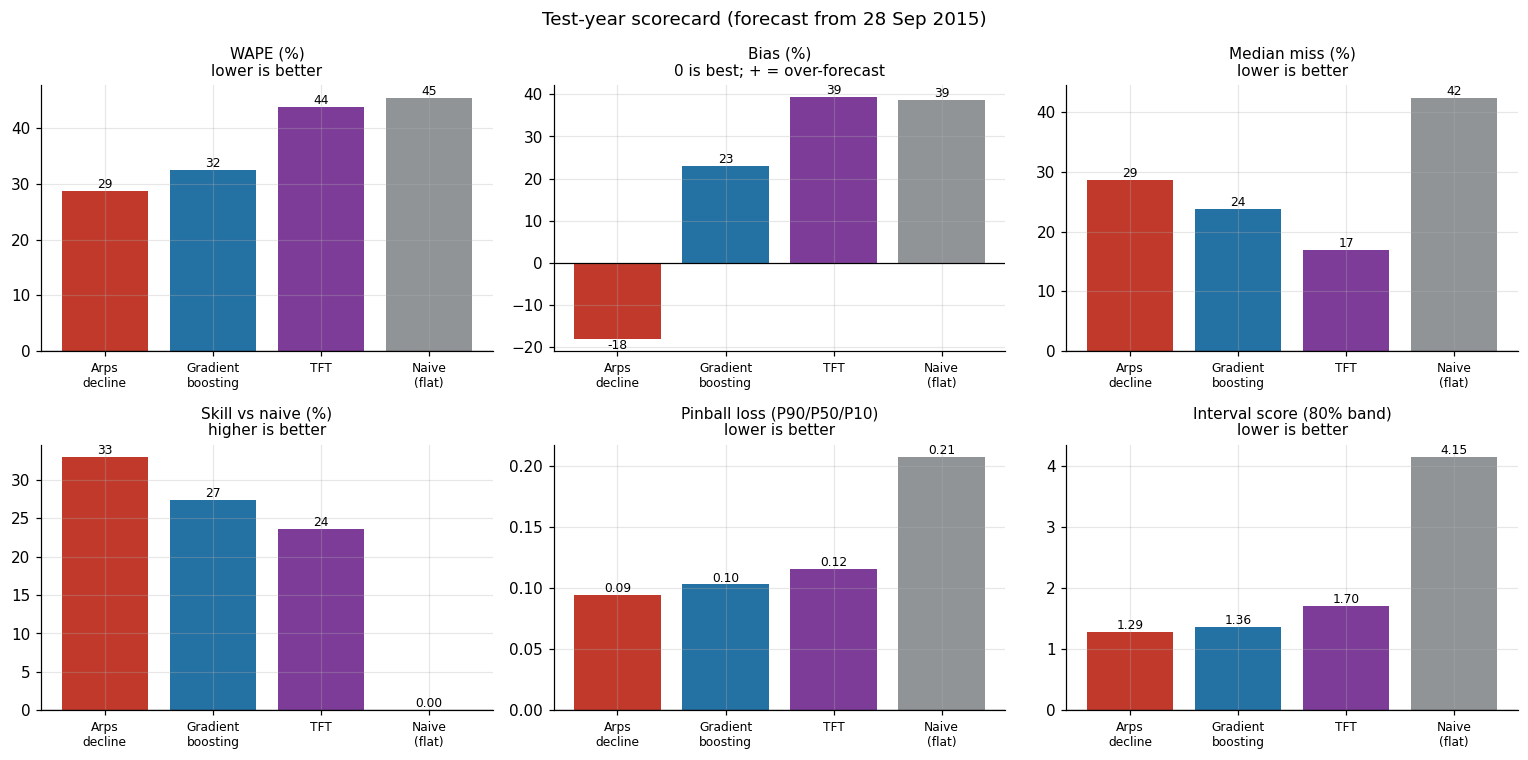

In [29]:
# 11b. Chart: test-year scorecard, every metric side by side
COLORS["Naive (flat)"] = "#909497"
sc_methods = list(scorecard.index)
panels = [("WAPE_%", "WAPE (%)\nlower is better"), ("bias_%", "Bias (%)\n0 is best; + = over-forecast"),
          ("median_log_err_%", "Median miss (%)\nlower is better"), ("skill_vs_naive_%", "Skill vs naive (%)\nhigher is better"),
          ("pinball_loss", "Pinball loss (P90/P50/P10)\nlower is better"), ("interval_score", "Interval score (80% band)\nlower is better")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, title) in zip(axes.ravel(), panels):
    vals = scorecard[col].values
    bars = ax.bar(range(len(sc_methods)), vals, color=[COLORS[m] for m in sc_methods])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(sc_methods)), [m.replace(" ", "\n", 1) for m in sc_methods], fontsize=8)
    ax.set_title(title, fontsize=10)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.2f}" if abs(v) < 5 else f"{v:.0f}", (b.get_x() + b.get_width() / 2, v),
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
fig.suptitle("Test-year scorecard (forecast from 28 Sep 2015)", fontsize=12)
fig.tight_layout(); save(fig, "10_scorecard.png"); plt.show()

- rolling backtest, a new forecast every quarter from 2009 to 2015

In [30]:
# 11c. Rolling backtest: re-run every model from a new forecast date each quarter (2009-2015)
# Each forecast date uses ONLY data before it, exactly like the main test. Nothing here is tuned.
import functools
ROLL_ORIGINS = sorted(TEST_ORIGIN - pd.Timedelta(weeks=13 * k) for k in range(25))   # every 13 weeks, ~6 years
RUN_TFT_ROLLING = "TFT" in FORECASTS["test"]   # set to False to skip the TFT (saves ~10-20 min)
TFT_ROLL_EPOCHS = 30                           # fewer epochs and 1 seed per date, to keep run time sensible

def per_origin_scores(df, origin, method):
    df = df[df["actual"].notna() & ~df["after_jump"]]
    rows = []
    for well, g in df.groupby("well"):
        a, p = g["actual"].values, g["p50"].values
        la = np.log(a)
        qs = np.log(np.column_stack([g["lo"], g["p50"], g["hi"]]))
        e = la[:, None] - qs
        rows.append({"origin": origin, "well": well, "method": method, "weeks": len(g),
                     "log_err": np.mean(np.abs(np.log(p) - la)),
                     "wape_%": np.abs(p - a).sum() / a.sum() * 100,
                     "bias_%": (p.sum() - a.sum()) / a.sum() * 100,
                     "coverage_%": ((a >= g["lo"]) & (a <= g["hi"])).mean() * 100,
                     "pinball": np.maximum(Q * e, (Q - 1) * e).mean()})
    return rows

roll_rows = []
t_start = time.time()
for k, origin in enumerate(ROLL_ORIGINS, 1):
    runs = {"Arps decline": arps_forecast(origin, n_boot=100)[0],
            "Gradient boosting": gbm_forecast(origin)[0],
            "Naive (flat)": naive_forecast(origin)}
    if RUN_TFT_ROLLING:
        _train_full = train_tft
        train_tft = functools.partial(_train_full, epochs=TFT_ROLL_EPOCHS)
        try:
            runs["TFT"] = tft_forecast(origin, seeds=(0,))[0]
        finally:
            train_tft = _train_full
    for m, df in runs.items():
        roll_rows += per_origin_scores(df, origin, m)
    print(f"[{k:2d}/{len(ROLL_ORIGINS)}] forecast date {origin.date()} done  ({time.time() - t_start:.0f}s so far)")

roll = pd.DataFrame(roll_rows)
roll = roll[roll["weeks"] >= 8]                 # need at least 8 scored weeks to judge a forecast
roll.to_csv(OUT / "rolling_backtest_scores.csv", index=False)
ROLL_METHODS = [m for m in ["Arps decline", "Gradient boosting", "TFT", "Naive (flat)"] if m in roll["method"].unique()]
summary_roll = roll.groupby("method").agg(forecasts=("log_err", "size"), mean_log_err=("log_err", "mean"),
                                          median_wape_pct=("wape_%", "median"), mean_bias_pct=("bias_%", "mean"),
                                          coverage_pct=("coverage_%", "mean"), pinball=("pinball", "mean")).loc[ROLL_METHODS]
print(f"\n{roll['origin'].nunique()} forecast dates x wells = {len(roll[roll['method'] == 'Arps decline'])} forecasts per method")
summary_roll.round(3)

  seed 0 epoch   0  quantile loss 0.1940
  seed 0 epoch  20  quantile loss 0.1595
  seed 0 epoch  29  quantile loss 0.1541
[ 1/25] forecast date 2009-10-05 done  (16s so far)
  seed 0 epoch   0  quantile loss 0.1784
  seed 0 epoch  20  quantile loss 0.1386
  seed 0 epoch  29  quantile loss 0.1305
[ 2/25] forecast date 2010-01-04 done  (34s so far)
  seed 0 epoch   0  quantile loss 0.1930
  seed 0 epoch  20  quantile loss 0.1320
  seed 0 epoch  29  quantile loss 0.1235
[ 3/25] forecast date 2010-04-05 done  (56s so far)
  seed 0 epoch   0  quantile loss 0.2344
  seed 0 epoch  20  quantile loss 0.1736
  seed 0 epoch  29  quantile loss 0.1684
[ 4/25] forecast date 2010-07-05 done  (80s so far)
  seed 0 epoch   0  quantile loss 0.2456
  seed 0 epoch  20  quantile loss 0.1713
  seed 0 epoch  29  quantile loss 0.1624
[ 5/25] forecast date 2010-10-04 done  (108s so far)
  seed 0 epoch   0  quantile loss 0.2455
  seed 0 epoch  20  quantile loss 0.1256
  seed 0 epoch  29  quantile loss 0.1208
[

,forecasts,mean_log_err,median_wape_pct,mean_bias_pct,coverage_pct,pinball
method,,,,,,
Arps decline,64,0.224,17.250,5.797,53.180,0.084
Gradient boosting,64,0.236,19.544,6.460,44.692,0.090
TFT,61,0.256,18.618,11.635,57.984,0.092
Naive (flat),67,0.328,31.409,31.029,0.000,0.164


- is any model really better than Arps?

In [31]:
# 11d. Is ML better than Arps across ALL forecast dates?  (paired, well-by-well and date-by-date)
from scipy.stats import binomtest, wilcoxon
piv = roll.pivot_table(index=["origin", "well"], columns="method", values="log_err").dropna()
rng = np.random.default_rng(0)
origins_sorted = np.array(sorted(piv.index.get_level_values("origin").unique()))
sig_rows = []
for m in [x for x in ROLL_METHODS if x != "Arps decline"]:
    d = (piv[m] - piv["Arps decline"])            # > 0 means worse than Arps
    wins, n = int((d < 0).sum()), len(d)
    # Block bootstrap: resample runs of 4 consecutive forecast dates (~1 year), because
    # neighbouring dates share overlapping forecast windows and are not independent.
    by_origin = d.groupby(level="origin").mean().reindex(origins_sorted).values
    blocks = [by_origin[i:i + 4] for i in range(len(by_origin) - 3)]
    boots = [np.nanmean(np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(by_origin) // 4 + 1)]))
             for _ in range(5000)]
    lo_ci, hi_ci = np.percentile(boots, [2.5, 97.5])
    sig_rows.append({"model": m, "better than Arps on": f"{wins} of {n}", "win rate %": 100 * wins / n,
                     "mean log-error difference": d.mean(), "95% CI low": lo_ci, "95% CI high": hi_ci,
                     "Wilcoxon p (indep. approx.)": wilcoxon(d).pvalue,
                     "verdict": ("better than Arps" if hi_ci < 0 else "worse than Arps" if lo_ci > 0
                                 else "no clear difference")})
significance = pd.DataFrame(sig_rows).set_index("model")
significance.round(3).to_csv(OUT / "rolling_significance.csv")
print("Negative difference = better than Arps. The block-bootstrap interval is the one to trust;")
print("the Wilcoxon p-value assumes independent forecasts, so it is optimistic here.")
significance.round(3)

Negative difference = better than Arps. The block-bootstrap interval is the one to trust;
the Wilcoxon p-value assumes independent forecasts, so it is optimistic here.


,better than Arps on,win rate %,mean log-error difference,95% CI low,95% CI high,Wilcoxon p (indep. approx.),verdict
model,,,,,,,
Gradient boosting,28 of 61,45.902,0.012,-0.041,0.041,0.399,no clear difference
TFT,24 of 61,39.344,0.031,-0.017,0.058,0.084,no clear difference
Naive (flat),12 of 61,19.672,0.108,0.054,0.136,0.000,worse than Arps


- rolling backtest charts

Saved figure: outputs/figures/11_rolling_backtest.png


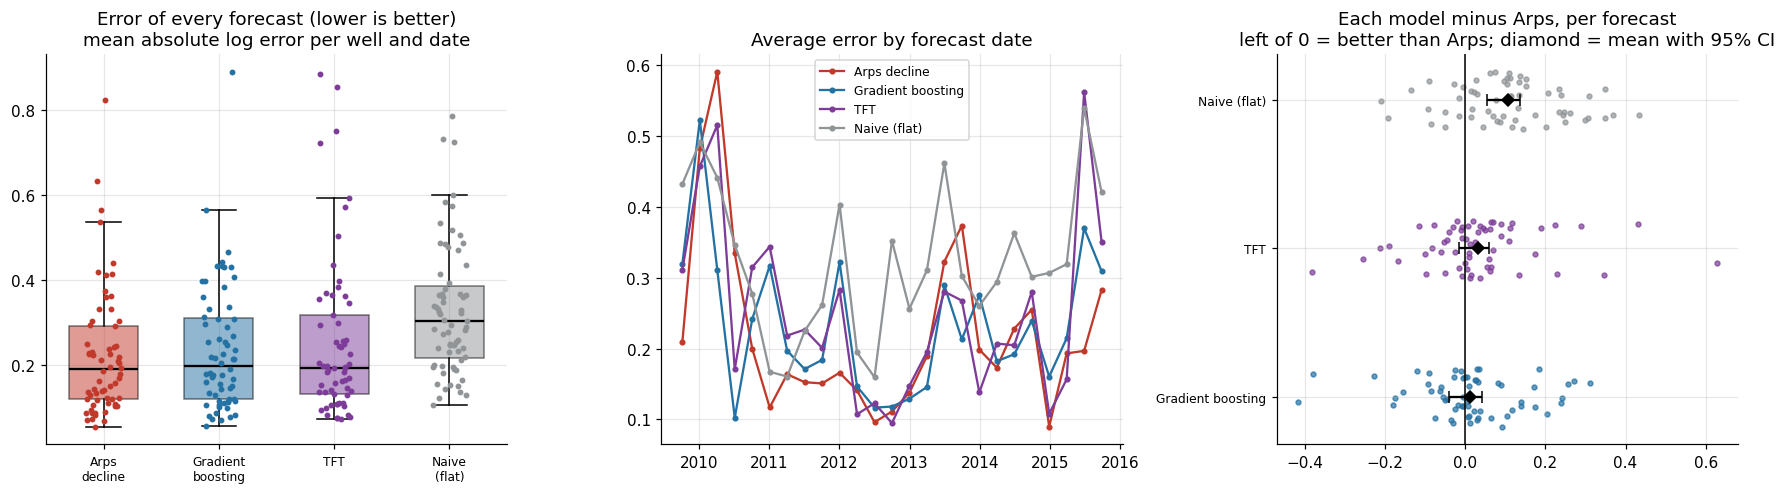

Saved figure: outputs/figures/12_win_rate_vs_arps.png


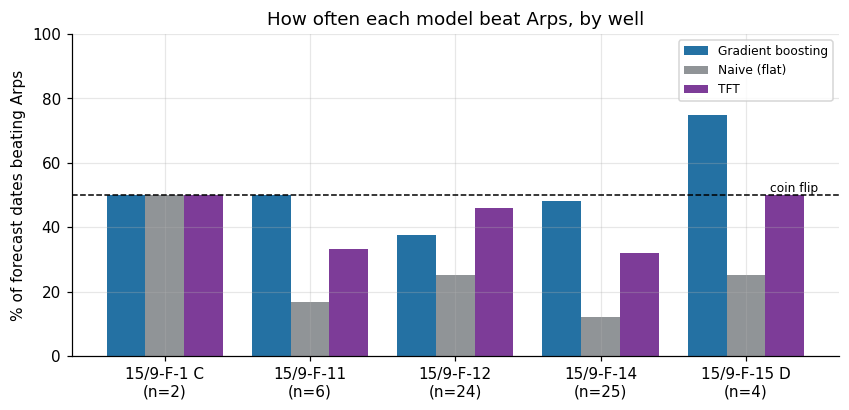

In [32]:
# 11e. Charts: rolling backtest
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
# (1) Distribution of errors per method
data = [roll.loc[roll["method"] == m, "log_err"].values for m in ROLL_METHODS]
bp = axes[0].boxplot(data, patch_artist=True, widths=0.6, showfliers=False, medianprops=dict(color="black", lw=1.5))
for patch, m in zip(bp["boxes"], ROLL_METHODS):
    patch.set_facecolor(COLORS[m]); patch.set_alpha(0.5)
for i, (m, v) in enumerate(zip(ROLL_METHODS, data), 1):
    axes[0].scatter(np.full(len(v), i) + rng.uniform(-0.15, 0.15, len(v)), v, s=8, color=COLORS[m], zorder=3)
axes[0].set_xticks(range(1, len(ROLL_METHODS) + 1), [m.replace(" ", "\n", 1) for m in ROLL_METHODS], fontsize=8)
axes[0].set_title("Error of every forecast (lower is better)\nmean absolute log error per well and date")
# (2) Error by forecast date
for m in ROLL_METHODS:
    s = roll[roll["method"] == m].groupby("origin")["log_err"].mean()
    axes[1].plot(s.index, s.values, marker="o", ms=3, color=COLORS[m], label=m)
axes[1].set_title("Average error by forecast date"); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_locator(mdates.YearLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
# (3) Paired difference vs Arps
for i, m in enumerate([x for x in ROLL_METHODS if x != "Arps decline"]):
    d = (piv[m] - piv["Arps decline"]).values
    axes[2].scatter(d, np.full(len(d), i) + rng.uniform(-0.2, 0.2, len(d)), s=10, color=COLORS[m], alpha=0.7)
    r = significance.loc[m] if m in significance.index else None
    if r is not None:
        axes[2].errorbar(r["mean log-error difference"], i, xerr=[[r["mean log-error difference"] - r["95% CI low"]],
                         [r["95% CI high"] - r["mean log-error difference"]]], fmt="D", color="k", capsize=4)
others = [x for x in ROLL_METHODS if x != "Arps decline"]
axes[2].set_yticks(range(len(others)), others, fontsize=8)
axes[2].axvline(0, color="k", lw=1)
axes[2].set_title("Each model minus Arps, per forecast\nleft of 0 = better than Arps; diamond = mean with 95% CI")
fig.tight_layout(); save(fig, "11_rolling_backtest.png"); plt.show()

# (4) Win rate against Arps, per well
win = (piv.drop(columns="Arps decline").lt(piv["Arps decline"], axis=0)
         .groupby(level="well").mean() * 100)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(win.index)); wdt = 0.8 / len(win.columns)
for j, m in enumerate(win.columns):
    ax.bar(x + j * wdt - 0.4 + wdt / 2, win[m].values, wdt, color=COLORS[m], label=m)
ax.axhline(50, color="k", ls="--", lw=1); ax.text(len(x) - 0.5, 51, "coin flip", ha="right", fontsize=8)
n_per_well = piv.groupby(level="well").size()
ax.set_xticks(x, [f"{w}\n(n={n_per_well[w]})" for w in win.index]); ax.set_ylim(0, 100); ax.set_ylabel("% of forecast dates beating Arps")
ax.set_title("How often each model beat Arps, by well"); ax.legend(fontsize=8)
save(fig, "12_win_rate_vs_arps.png"); plt.show()